In [16]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [17]:
dataset_path = "Laliga teams/Laliga teams"

img_size = (128, 128)
batch_size = 32
seed = 42

In [18]:
train_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

val_data = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=img_size,
    batch_size=batch_size
)

class_names = train_data.class_names

print("Daftar kelas:")
print(class_names)

print("Jumlah kelas:", len(class_names))

Found 2000 files belonging to 20 classes.
Using 1600 files for training.
Found 2000 files belonging to 20 classes.
Using 400 files for validation.
Daftar kelas:
['Athletic Bilbao', 'Atletico Madrid', 'Barcelona', 'Celta Vigo', 'Deportivo Alaves', 'Espanyol', 'Getafe', 'Girona', 'Las Palmas', 'Leganes', 'Mallorca', 'Osasuna', 'Rayo Vallecano', 'Real Betis', 'Real Madrid', 'Real Sociedad', 'Real Valladolid', 'Sevilla', 'Valencia', 'Villarreal']
Jumlah kelas: 20


In [19]:
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(
    buffer_size=AUTOTUNE
)

val_data = val_data.prefetch(
    buffer_size=AUTOTUNE
)

In [20]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(
        shape=(128, 128, 3)
    ),

    # Normalisasi gambar
    tf.keras.layers.Rescaling(1.0 / 255),

    # Convolution Layer 1
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Layer 2
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # Convolution Layer 3
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation="relu"
    ),

    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),

    # Mengubah feature map menjadi vektor
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    # Mengurangi overfitting
    tf.keras.layers.Dropout(0.3),

    # Output untuk 20 kelas
    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )
])

In [21]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Menampilkan struktur model
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 20)             │         2,580 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,307,220 (12.62 MB)

 Trainable params: 3,307,220 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20
)

Epoch 1/20


c:\Users\Adrian Majid\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 254ms/step - accuracy: 0.5194 - loss: 1.6974 - val_accuracy: 0.9900 - val_loss: 0.0853
Epoch 2/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 258ms/step - accuracy: 0.9762 - loss: 0.0812 - val_accuracy: 1.0000 - val_loss: 0.0076
Epoch 3/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 259ms/step - accuracy: 0.9906 - loss: 0.0293 - val_accuracy: 1.0000 - val_loss: 0.0010
Epoch 4/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 258ms/step - accuracy: 0.9956 - loss: 0.0163 - val_accuracy: 1.0000 - val_loss: 2.7152e-05
Epoch 5/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 256ms/step - accuracy: 0.9987 - loss: 0.0062 - val_accuracy: 1.0000 - val_loss: 2.7386e-05
Epoch 6/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 259ms/step - accuracy: 0.9862 - loss: 0.0494 - val_accuracy: 0.9900 - val_loss: 0.0279
Epoch 7/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 260ms/step - accuracy: 0.9925 - loss: 0.0278 - val_accuracy: 1.0000 - val_loss: 5.1946e-05
Epoch 8/20
50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 264ms/step - accuracy: 0.9975 - loss: 0.0081 - val_acc

In [23]:
loss, accuracy = model.evaluate(val_data)

print("\nHasil Evaluasi Model")
print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy * 100, "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 1.0000 - loss: 1.2774e-04

Hasil Evaluasi Model
Validation Loss: 0.00012774206697940826
Validation Accuracy: 100.0 %


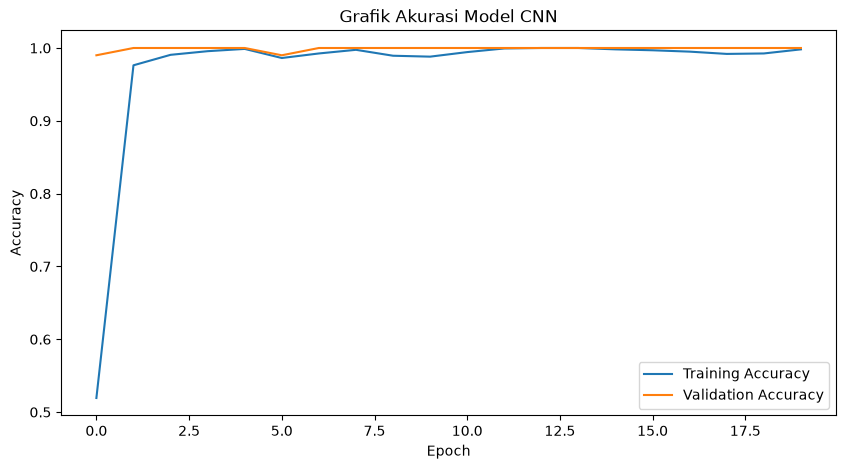

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Grafik Akurasi Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

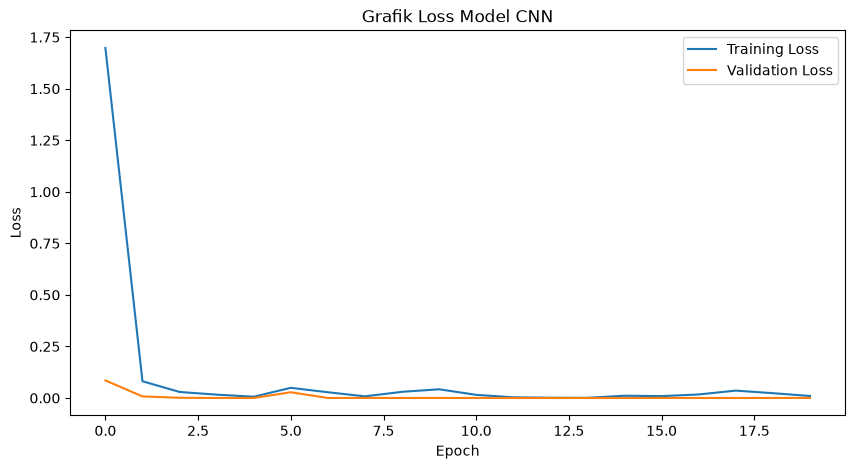

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Grafik Loss Model CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


Classification Report
                  precision    recall  f1-score   support

 Athletic Bilbao       1.00      1.00      1.00        16
 Atletico Madrid       1.00      1.00      1.00        18
       Barcelona       1.00      1.00      1.00        23
      Celta Vigo       1.00      1.00      1.00        14
Deportivo Alaves       1.00      1.00      1.00        19
        Espanyol       1.00      1.00      1.00        16
          Getafe       1.00      1.00      1.00        22
          Girona       1.00      1.00      1.00        20
      Las Palmas       1.00      1.00      1.00        21
         Leganes       1.00      1.00      1.00        13
        Mallorca       1.00      1.00      1.00        21
         Osasuna       1.00      1.00      1.00        22
  Rayo Vallecano       1.00      1.00      1.00        19
      Real Betis       1.00      1.00      1.00        19
     Real Madrid       1.00      1.00      1.00        26
   Real Sociedad       1.00      1.00      1.00 

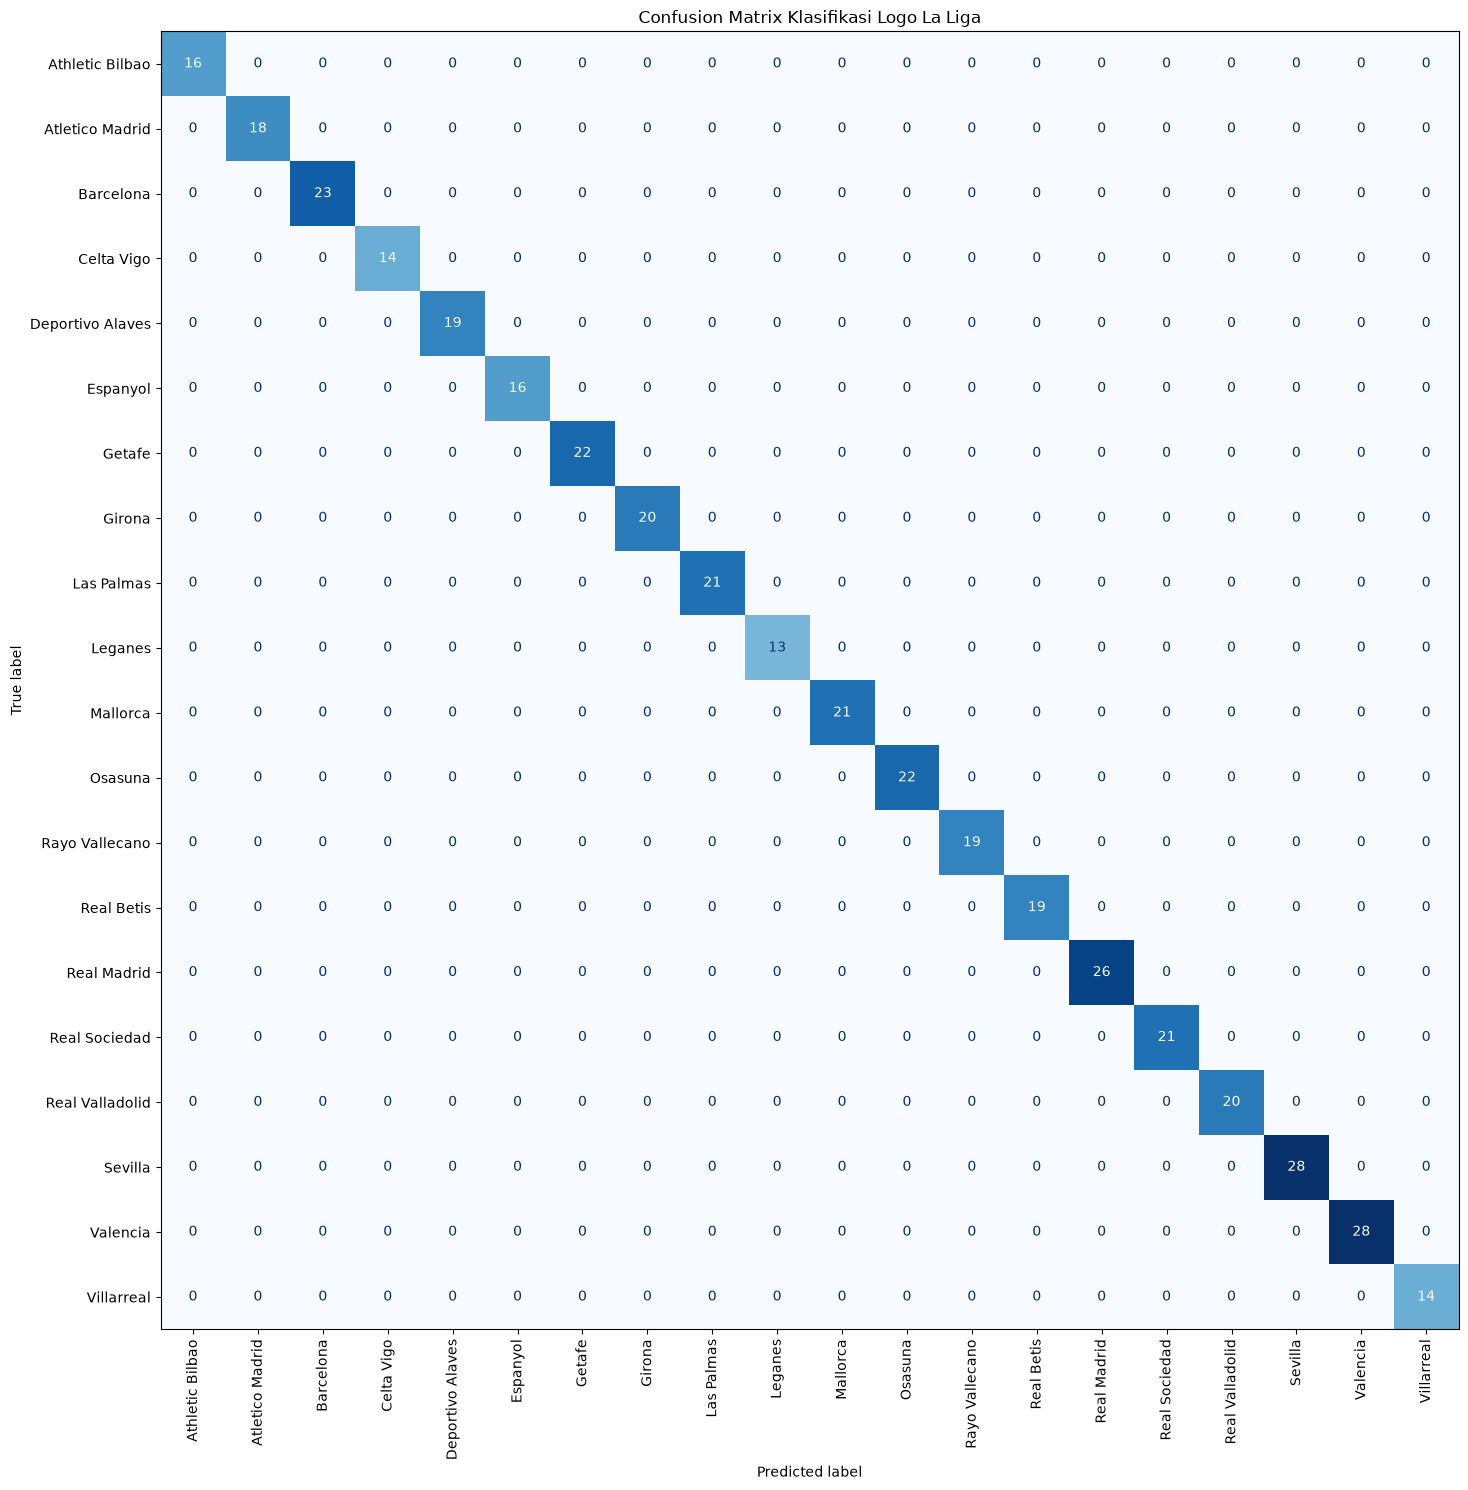

In [26]:
y_true = []
y_pred = []

for images, labels in val_data:

    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print("\nClassification Report")

print(
    classification_report(
        y_true,
        y_pred,
        labels=range(len(class_names)),
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(15, 15))

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)

plt.title("Confusion Matrix Klasifikasi Logo La Liga")
plt.tight_layout()
plt.show()

In [27]:
model.save("model_laliga.keras")

print("\nModel berhasil disimpan!")


Model berhasil disimpan!
